In [1]:
.libPaths()

[1] "/home/lab401_B/anaconda3/envs/R_4.0.3/lib/R/library"

In [1]:
library("Seurat")
library(harmony)
library(cowplot)

Attaching SeuratObject

Loading required package: Rcpp



In [2]:
# 读取RDS文件
human_data <- readRDS("/home/lab401_B/scRNA_downstream/10xproject/scRNA_species/2024.12.3_new/human_main_female_subsetted.rds")
monkey_data <- readRDS("/home/lab401_B/scRNA_downstream/10xproject/scRNA_species/2024.12.3_new/Monkey_integrated_seuratobj_humanorthlog.rds")
mouse_data <- readRDS("/home/lab401_B/scRNA_downstream/10xproject/scRNA_species/2024.12.3_new/Mouse_integrated_seuratobj_humanorthlog.rds")
pig_data <- readRDS("/home/lab401_B/scRNA_downstream/10xproject/scRNA_species/2024.12.3_new/Pig_integrated_seuratobj_humanorthlog.rds")

In [6]:
# check size 
human_data
monkey_data
mouse_data
pig_data

An object of class Seurat 
28820 features across 49043 samples within 1 assay 
Active assay: RNA (28820 features, 0 variable features)
 2 dimensional reductions calculated: scVI, umap

An object of class Seurat 
12066 features across 9700 samples within 1 assay 
Active assay: RNA (12066 features, 2000 variable features)

An object of class Seurat 
15498 features across 12000 samples within 1 assay 
Active assay: RNA (15498 features, 2000 variable features)

An object of class Seurat 
11771 features across 18956 samples within 1 assay 
Active assay: RNA (11771 features, 2000 variable features)

In [8]:
seurat_list <- list(human_data,monkey_data,mouse_data,pig_data)

In [ ]:
### 1. using defaul batch correcting method 

In [9]:
anchor <- FindIntegrationAnchors(object.list = seurat_list, dims = 1:30,anchor.features = 1500)  
cell_total <- IntegrateData(anchorset = anchor, dims = 1:30)


Computing 1500 integration features

No variable features found for object1 in the object.list. Running FindVariableFeatures ...

Scaling features for provided objects

Finding all pairwise anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 30816 anchors

Filtering anchors

	Retained 9179 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 33186 anchors

Filtering anchors

	Retained 5769 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 21214 anchors

Filtering anchors

	Retained 3274 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 48246 anchors

Filtering anchors

	Retained 6577 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 24629 anchors

Filtering anchors

	Retained 3010 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 25408 anchors

Filtering anchors

	Retained 2615 

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
15:20:49 UMAP embedding parameters a = 0.9922 b = 1.112

15:20:49 Read 89699 rows and found 20 numeric columns

15:20:49 Using Annoy for neighbor search, n_neighbors = 30

15:20:49 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:21:01 Writing NN index file to temp file /tmp/RtmpLXUKOV/file598cf4fec42af

15:21:01 Searching Annoy index using 1 thread, search_k = 3000

15:21:55 Annoy recall = 100%

15:21:56 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 89699
Number of edges: 2894229

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9137
Number of communities: 19
Elapsed time: 44 seconds


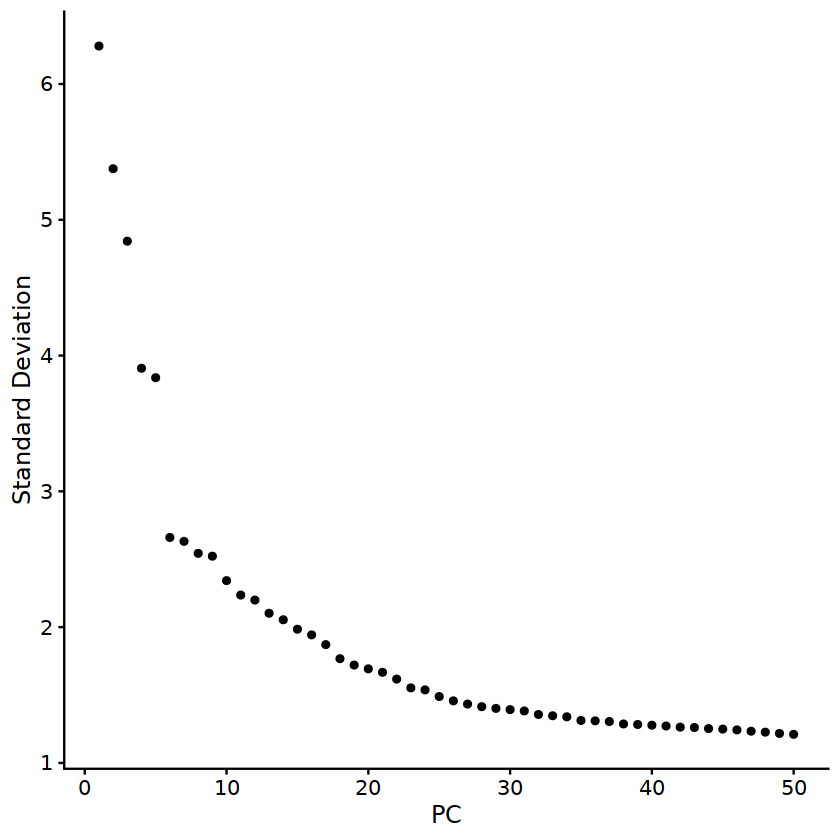

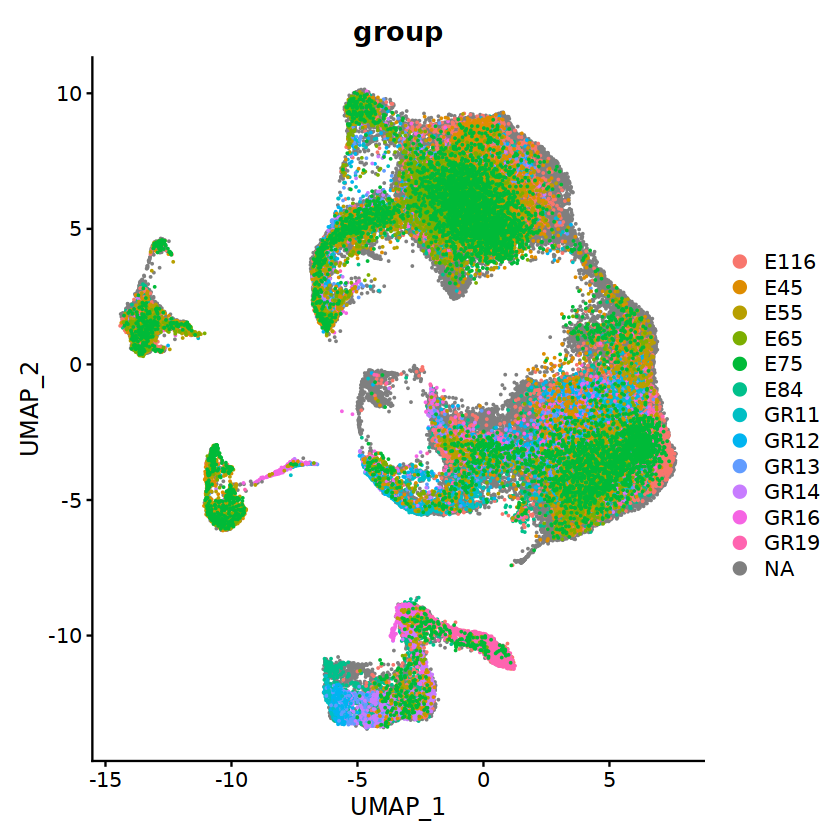

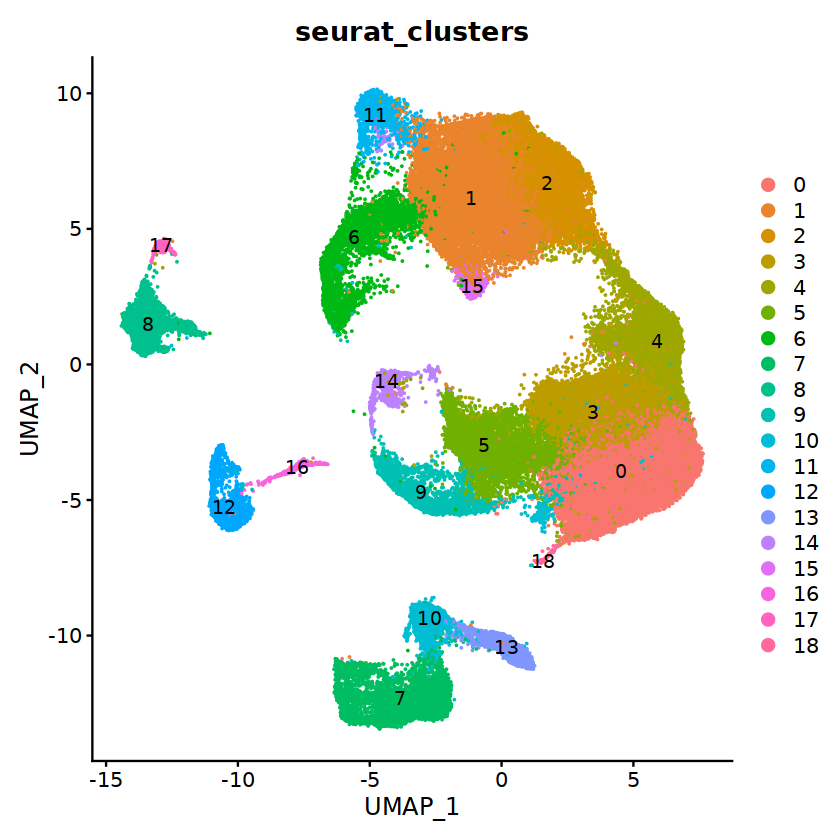

In [10]:
DefaultAssay(cell_total) <- "integrated"
### PCA
cell_total <- ScaleData(cell_total, verbose = FALSE)
cell_total <- RunPCA(cell_total, verbose = FALSE,npcs = 50)
ElbowPlot(cell_total,ndims = 50)   
### visulization
cell_total <- RunUMAP(cell_total,reduction = "pca", dims = 1:20)
cell_total <- FindNeighbors(cell_total, reduction = "pca", dims = 1:20)
cell_total <- FindClusters(cell_total, resolution = 0.5)
### set the defined color 
### Dimplot to show the clusters 

DimPlot(cell_total, reduction = "umap", label = FALSE, group.by = "group")
DimPlot(cell_total, reduction = "umap", label = T, group.by = "seurat_clusters")

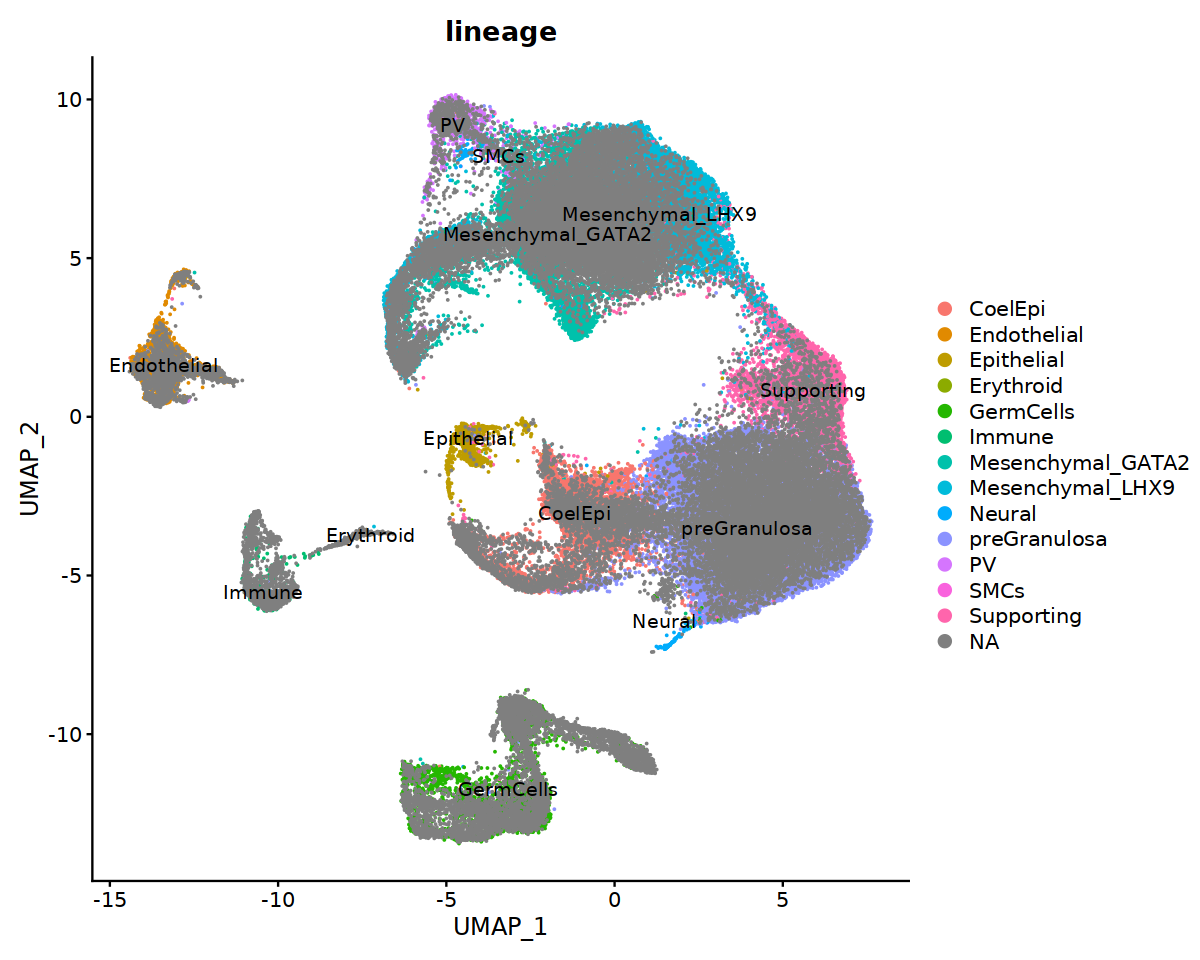

In [12]:
options(repr.plot.width=10,repr.plot.height=8)
#DimPlot(seurat_obj,reduction = "umap",label = T)
DimPlot(cell_total,reduction = "umap",label = T,group.by = "lineage")

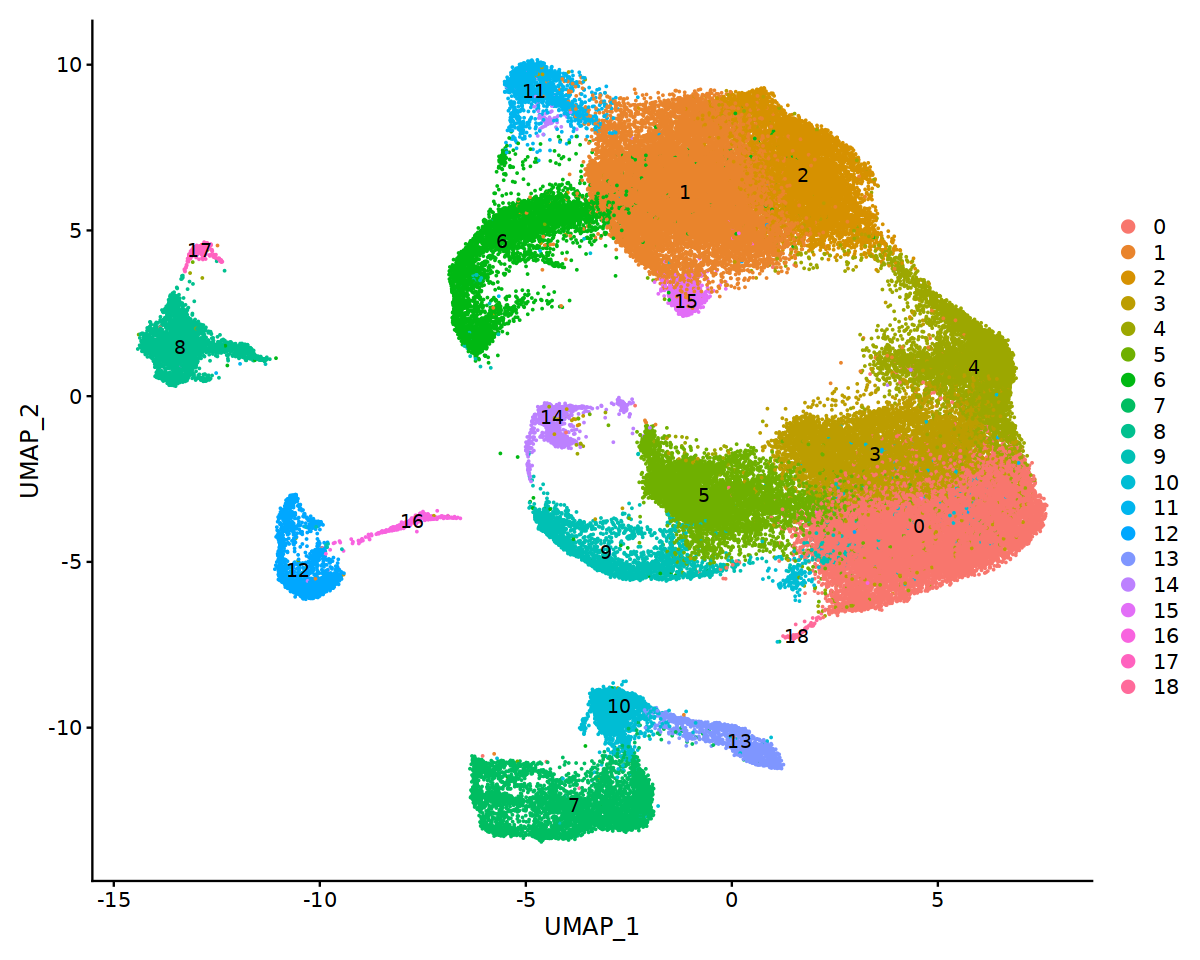

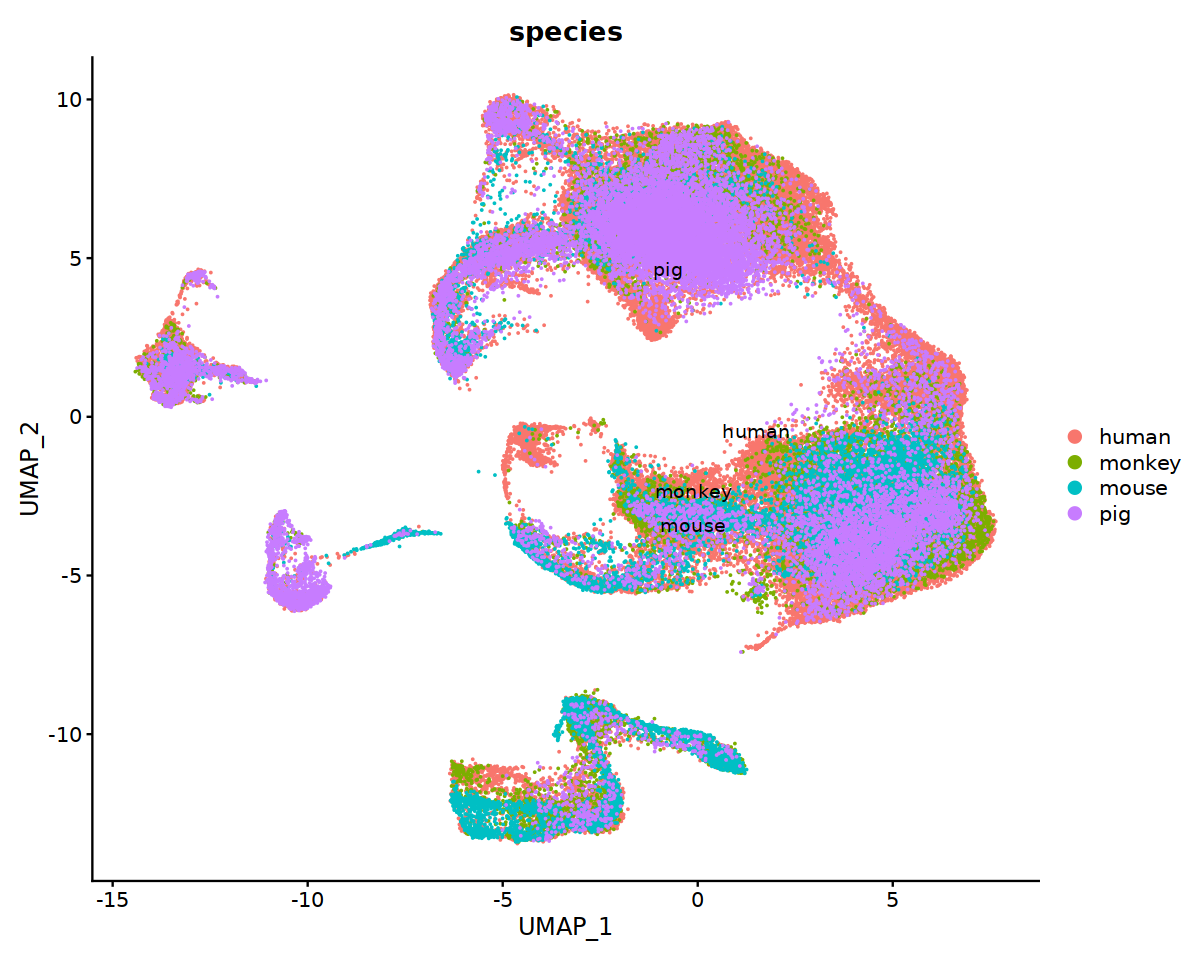

In [13]:
options(repr.plot.width=10,repr.plot.height=8)
DimPlot(cell_total,reduction = "umap",label = T)
DimPlot(cell_total,reduction = "umap",label = T,group.by = "species")

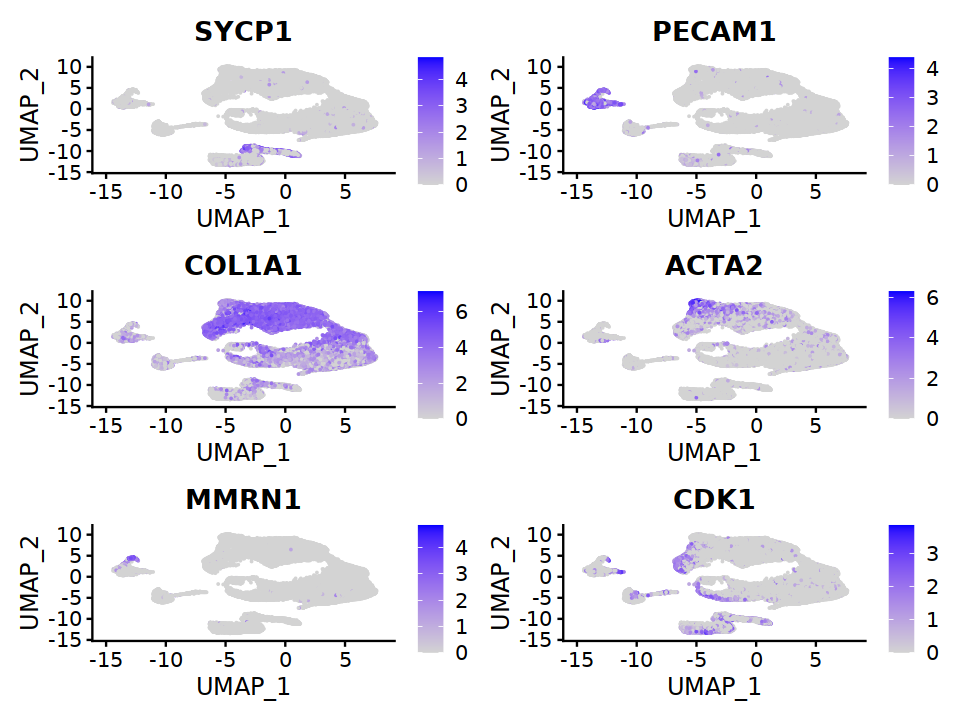

In [17]:
DefaultAssay(cell_total) <- "RNA"
options(repr.plot.width=8,repr.plot.height=6)
FeaturePlot(cell_total, features = c("SYCP1","PECAM1","COL1A1","ACTA2","MMRN1","CDK1"))
#FeaturePlot(seurat_obj, features = c("PECAM1"))

In [ ]:
# 看起来上面这个效果更好，保存相应的RDS文件

In [14]:
saveRDS(cell_total,file = "/home/lab401_B/scRNA_downstream/10xproject/scRNA_species/2024.12.3_new/all_species_integrated_anchor.rds")
#seurat_obj<-readRDS(file = "E:\\Lab of Germ Cell Bio\\10xSpatial_transcriptome\\9.Results\\integrted.rds")